# 第 05 关：三因子模型改善了什么？

**本关要回答的问题：** 在市场因子之外加入 SMB 和 HML，25 个规模×B/M 组合的定价误差是否明显缩小？

### 三因子模型
对每个组合做回归：

$$
R_{i,t}-R_{f,t}=\alpha_i+b_i(R_{M,t}-R_{f,t})+s_i\,SMB_t+h_i\,HML_t+\varepsilon_{i,t}.
$$

$b_i$、$s_i$、$h_i$ 分别是组合对市场、规模、价值因子的暴露，表中记为 `beta_Mkt-RF`、`beta_SMB`、`beta_HML`。$s_i$ 大，说明这个组合的收益像小公司股票一样变动；$h_i$ 大，说明它像价值股一样变动。

和第 03 关的推导一样，把回归在样本期内取平均，得到

$$
\overline{R_i-R_f}=\alpha_i+b_i\,\overline{MKT}+s_i\,\overline{SMB}+h_i\,\overline{HML}.
$$

模型的含义是：平均超额收益 = 对三个因子的暴露 × 各因子的平均收益。α 仍然是定价误差，模型成立时应该为零。

### 本关的评价指标
- **平均绝对 α**、**α 均方根**：25 个 α 分别取绝对值的平均、取平方的平均再开方，单位 %/月，衡量定价误差的整体大小。均方根对少数大误差更敏感。
- **平均 R²**：因子解释了组合月度波动的多大比例。
- **GRS 检验**：检验"25 个 α 同时为零"，第 3 节详细介绍。

本关对照 FF1993 **Table 6**（暴露与调整 R²）和 **Table 9a(iv)**（α），样本 1963-07 至 1991-12。

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/course.py').exists())
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from course import (load_raw, load_returns, raw_path, catalog, manifest, style,
                    build_ff3, build_ff5, heatmap25, save_table, paper_note)
from analysis import fit_models, grs_test, model_summary
style()
print('项目目录：', ROOT)

项目目录： E:\Eth data\asset_pricing_quest


In [2]:
display(Markdown(paper_note('ff1993')))

**论文对照：** [Fama & French (1993), Common risk factors in the returns on stocks and bonds](../papers/ff1993_primary_reference.pdf)。准确表号、PDF 页码和复现范围见 [论文表格导航](../papers/TABLE_GUIDE.md)。当前数据版本会与原文历史版本存在差异。

## 1. 在同一样本、同一批资产上比较 CAPM 与三因子
两个模型用完全相同的月份和 25 个组合，所以误差的变化只来自"多了两个因子"。

第一张表是模型汇总：`mean_abs_alpha_pct_month` 是平均绝对 α，`rms_alpha_pct_month` 是 α 均方根（都是 %/月）；`mean_r2` 是平均 R²；`grs_stat`、`grs_pvalue` 是 GRS 统计量和 p 值；`T`、`N`、`K` 分别是月份数、资产数、因子数。第二张表是三因子模型下每个组合的回归结果，列名含义同第 03 关。

In [3]:
ff = load_returns('ff3','1963-07','1991-12')
p = load_returns('bm25','1963-07','1991-12')
y = p.sub(ff.RF,axis=0)
models = {'CAPM':ff[['Mkt-RF']],'FF3':ff[['Mkt-RF','SMB','HML']]}
summary = model_summary(y,models)
display(summary)
capm,_ = fit_models(y,models['CAPM'])
ff3,residuals = fit_models(y,models['FF3'])
display(ff3[['alpha_pct_month','beta_Mkt-RF','beta_SMB','beta_HML','t_alpha_ols','t_alpha_hac','adj_r2']])
save_table(summary,'05_capm_vs_ff3')
save_table(ff3,'05_ff1993_table6_ff3')

,mean_abs_alpha_pct_month,rms_alpha_pct_month,mean_r2,grs_stat,grs_pvalue,T,N,K
model,,,,,,,,
CAPM,0.2569,0.3044,0.7943,1.9848,0.0040,342,25,1
FF3,0.0937,0.1200,0.9342,1.4318,0.0861,342,25,3


,alpha_pct_month,beta_Mkt-RF,beta_SMB,beta_HML,t_alpha_ols,t_alpha_hac,adj_r2
asset,,,,,,,
SMALL LoBM,-0.3677,1.0347,1.4182,-0.2851,-3.4281,-3.1253,0.9380
ME1 BM2,-0.0967,0.9657,1.2787,0.0840,-1.2256,-1.3606,0.9561
ME1 BM3,-0.0499,0.9451,1.1565,0.2794,-0.7461,-0.7411,0.9633
ME1 BM4,0.0608,0.8976,1.1065,0.3938,1.0068,0.9761,0.9662
SMALL HiBM,0.0584,0.9509,1.1905,0.6152,0.8793,0.8977,0.9636
ME2 BM1,-0.1396,1.1026,1.0016,-0.4727,-1.6569,-1.7392,0.9566
ME2 BM2,-0.0315,1.0224,0.9367,0.0326,-0.4544,-0.4402,0.9605
ME2 BM3,0.1291,0.9655,0.8481,0.2387,1.9508,1.9118,0.9568
ME2 BM4,0.1434,0.9654,0.7026,0.4711,2.3014,2.4776,0.9558


WindowsPath('E:/Eth data/asset_pricing_quest/results/05_ff1993_table6_ff3.csv')

**怎么读：**
- 平均绝对 α 从 CAPM 的约 0.26 降到三因子的约 0.09 个百分点/月，减少了约三分之二；平均 R² 从 0.79 升到 0.93。
- 第二张表中，`beta_SMB` 从小盘到大盘依次下降，`beta_HML` 从低 B/M 到高 B/M 依次上升：组合的因子暴露与它的特征排序一一对应。这正是三因子能解释平均收益差异的原因：小盘、价值组合对 SMB、HML 的暴露更高，而 SMB、HML 的平均收益为正，于是模型预测它们的平均收益更高。
- 例外是左上角的 `SMALL LoBM`（小盘成长）：三因子下 α 仍约 −0.37%/月，t 值约 −3.4。这个组合是三因子模型最著名的难题，第 08 关还会遇到它。

## 2. 改善发生在哪些组合？
两幅热力图使用相同的色阶：左边是 CAPM 的 α，右边是三因子的 α，单位 %/月。格子里的数是截距，不是平均收益。

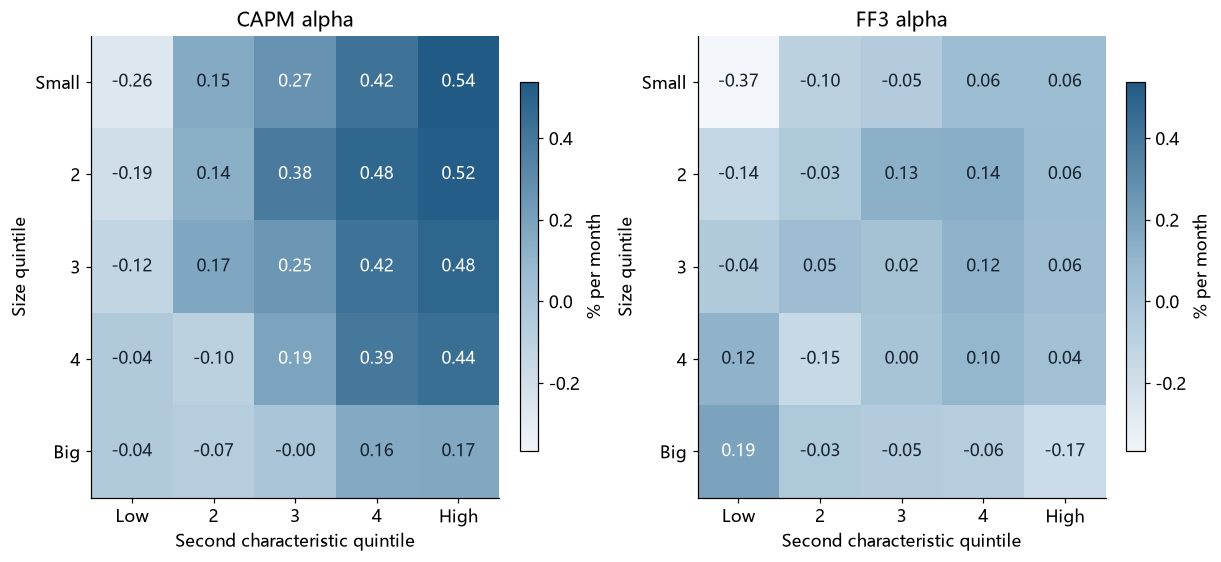

**读数：** 平均绝对 α 从 **0.257** 降到 **0.094 个百分点/月**。CAPM 图中“越往右颜色越深”的价值效应，在三因子图中基本消失，大多数格子接近 0；仍然显眼的是左上角的小盘成长组合。

In [4]:
fig, axes = plt.subplots(1,2,figsize=(11,5),layout='constrained')
lo = min(capm.alpha_pct_month.min(),ff3.alpha_pct_month.min())   # 两图共用色阶，颜色才可比
hi = max(capm.alpha_pct_month.max(),ff3.alpha_pct_month.max())
heatmap25(capm.alpha_pct_month,'CAPM alpha','% per month',ax=axes[0],vmin=lo,vmax=hi)
heatmap25(ff3.alpha_pct_month,'FF3 alpha','% per month',ax=axes[1],vmin=lo,vmax=hi)
plt.show()
a,b = summary.loc['CAPM','mean_abs_alpha_pct_month'],summary.loc['FF3','mean_abs_alpha_pct_month']
display(Markdown(f'**读数：** 平均绝对 α 从 **{a:.3f}** 降到 **{b:.3f} 个百分点/月**。CAPM 图中“越往右颜色越深”的价值效应，在三因子图中基本消失，大多数格子接近 0；仍然显眼的是左上角的小盘成长组合。'))

## 3. GRS 联合检验：25 个 α 是否同时为零？
逐个看 25 个 t 值有两个问题：一是做 25 次检验，碰巧出现一两个显著的很正常；二是组合之间的残差高度相关，25 次检验并不独立。**GRS 检验**（Gibbons, Ross & Shanken 1989）把所有 α 合成一个统计量：

$$
G=\frac{T-N-K}{N}\cdot\frac{\hat\alpha'\hat\Sigma^{-1}\hat\alpha}{1+\bar f'\hat\Omega^{-1}\bar f}.
$$

符号：$T$ 是月份数，$N$ 是资产数，$K$ 是因子数；$\hat\alpha$ 是 $N$ 个 α 组成的向量；$\hat\Sigma$ 是残差的协方差矩阵；$\bar f$ 是因子的样本均值向量，$\hat\Omega$ 是因子的协方差矩阵（两个协方差都以 $T$ 为分母）。

直观理解：
- **分子** $\hat\alpha'\hat\Sigma^{-1}\hat\alpha$ 是"按残差噪声标准化之后 α 的总大小"。残差噪声小的组合，同样大的 α 更难用运气解释，因此分量更重；彼此高度相关的组合也不会被重复计算。
- **分母** 修正因子均值带来的估计误差。$\bar f'\hat\Omega^{-1}\bar f$ 是用这几个因子能组合出的最大夏普比率的平方；因子的平均收益相对其波动越大，α 的估计就越不精确，所以要除掉这一部分。

在残差服从正态分布、各月相互独立的经典假设下，$G$ 服从自由度为 $(N,\,T-N-K)$ 的 F 分布。表中 `pvalue` 是"如果所有 α 真的都为零，得到至少这么大的 $G$ 的概率"。p 值小于 0.05 时，通常拒绝"所有 α 都为零"。

计算细节见 `src/analysis.py`。GRS 使用普通的残差协方差，与单个 α 的 HAC t 值是两种不同的推断方法。

In [5]:
joint = grs_test(y,models['FF3'])
display(pd.Series(joint).to_frame('FF3 joint test'))
decision = '拒绝' if joint['pvalue']<.05 else '不能拒绝'
display(Markdown(
    f'在 5% 显著性水平下，**{decision}**“三因子模型的 25 个 α 同时为零”这一原假设'
    f'（GRS = {joint["stat"]:.3f}，p = {joint["pvalue"]:.4g}）。'
    f'作为对照，上面汇总表中 CAPM 的 p 值为 {summary.loc["CAPM","grs_pvalue"]:.4g}，被明确拒绝。'
    '“不能拒绝”的意思是现有数据不足以说明模型错了，并不等于证明了模型正确。'))

,FF3 joint test
stat,1.4318
pvalue,0.0861
T,342.0000
N,25.0000
K,3.0000
df1,25.0000
df2,314.0000


在 5% 显著性水平下，**不能拒绝**“三因子模型的 25 个 α 同时为零”这一原假设（GRS = 1.432，p = 0.08608）。作为对照，上面汇总表中 CAPM 的 p 值为 0.004012，被明确拒绝。“不能拒绝”的意思是现有数据不足以说明模型错了，并不等于证明了模型正确。

## 4. 与原文对照
暴露和调整 R² 对照 **Table 6**（PDF 第 22–23 页），α 对照 **Table 9a(iv)**（PDF 第 35 页）。下面以 `SMALL LoBM` 为例：`原表` 是表号，`指标` 是对应的列，`当前减原文` 很小，说明重算结果与原文一致。

（原文 Table 9c 的 GRS 检验同时包含 25 个股票组合和 7 个债券组合，所以本关只有 25 个股票组合的 GRS 不与它直接比较。）

In [6]:
import json
anchors = json.loads((ROOT/'papers/paper_map.json').read_text(encoding='utf-8'))['numeric_anchors']

rows = []
for a in anchors:
    if a['paper']=='ff1993' and a.get('model')=='FF3_classic':
        field = {'market_beta':'beta_Mkt-RF','adjusted_r_squared':'adj_r2','alpha':'alpha_pct_month'}[a['metric']]
        current = ff3.loc[a['key'],field]
        rows.append({'原表':a['table'],'指标':field,'原文':a['paper_value'],'当前快照':current,'当前减原文':current-a['paper_value']})
display(pd.DataFrame(rows))
save_table(pd.DataFrame(rows),'05_original_ff3_anchors')

,原表,指标,原文,当前快照,当前减原文
0,6,beta_Mkt-RF,1.04,1.0347,-0.0053
1,6,adj_r2,0.94,0.9380,-0.0020
2,9a,alpha_pct_month,-0.34,-0.3677,-0.0277


WindowsPath('E:/Eth data/asset_pricing_quest/results/05_original_ff3_anchors.csv')

## 5. 结论能推到哪里
- **统计上**：三因子把 25 个规模×B/M 组合的平均定价误差缩小了约三分之二，并且在 5% 水平上未被 GRS 拒绝；CAPM 则被明确拒绝。
- **这批测试资产对三因子是"主场"**：SMB、HML 本来就是按规模和 B/M 构造的，用它们解释按同样特征排序的组合，效果好并不意外。更有说服力的检验需要换用按其他特征排序的资产（第 08 关）和其他时期（第 09 关）。
- **风险还是错误定价？** 回归只说明小盘、价值组合的平均收益与它们对 SMB、HML 的暴露相匹配。要说 SMB、HML 代表某种风险，还需要说明它们在什么经济状态下表现差，以及投资者为什么厌恶这种状态。

## Boss 作答区

写一段不超过 200 字的审稿意见：三因子相对 CAPM 的证据有哪些？还缺哪一种证据，才能把统计上的改善解释为风险补偿？

**我的回答：**

（由你填写；本课程未预填答案。）